In [ ]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
%matplotlib inline
import os
import shutil
from ctypes import *
import random
import math
import statistics
import seaborn as sns


from baybe.parameters import NumericalContinuousParameter
from baybe.searchspace import SearchSpace
from baybe.targets import NumericalTarget
from baybe.objectives import DesirabilityObjective
from baybe.targets import NumericalTarget
from baybe.objective import SingleTargetObjective
from baybe import Campaign

from baybe.recommenders import TwoPhaseMetaRecommender, RandomRecommender, BotorchRecommender
from baybe.recommenders import NaiveHybridSpaceRecommender, RandomRecommender
from baybe.recommenders.meta.sequential import TwoPhaseMetaRecommender
from baybe.constraints import (
    ContinuousLinearEqualityConstraint, ContinuousLinearInequalityConstraint, ThresholdCondition
)
from baybe.targets import NumericalTarget
np.random.seed(42)
from __future__ import annotations

import pickle
from pathlib import Path
from typing import Dict, Sequence, Tuple

import numpy as np
import matplotlib.pyplot as plt

from __future__ import annotations

import math
import pickle
from pathlib import Path
from typing import Iterable, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from matplotlib.font_manager import FontProperties
from matplotlib.collections import LineCollection

from baybe.parameters import NumericalContinuousParameter
from baybe.searchspace import SearchSpace
from baybe.targets import NumericalTarget
from baybe import Campaign
from baybe.recommenders import TwoPhaseMetaRecommender, RandomRecommender, BotorchRecommender
from baybe.constraints import ContinuousLinearInequalityConstraint

# NOTE: DesirabilityObjective is used below; import it explicitly
from baybe.objectives import DesirabilityObjective

### ## Load the trained surrogate model

This section loads a previously trained Polynomial Chaos Expansion (PCE) surrogate model for Alloy 718 yield strength prediction. The model file is not included in this demo repository. Users should update the `SURROGATE_MODEL_PATH` variable to point to the location of their own trained `.pkl` model.

The model expects alloy compositions in wt.% with the following element order:

`Ni, Cr, Nb, Al, Ti, Co, Mo`

In [ ]:
# ----------------------------
# Configuration
# ----------------------------

ELEMENTS: Tuple[str, ...] = ("Ni", "Cr", "Nb", "Al", "Ti", "Co", "Mo")

# Path to the trained PCE surrogate model.
# The actual model file is not included in this repository.
# Update this path to point to your local trained model.
SURROGATE_MODEL_PATH = Path("../model/pce_surrogate.pkl")


# ----------------------------
# Load surrogate model
# ----------------------------

if not SURROGATE_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Surrogate model file not found: {SURROGATE_MODEL_PATH.resolve()}\n"
        "Please update SURROGATE_MODEL_PATH to the location of your trained PCE model."
    )

with open(SURROGATE_MODEL_PATH, "rb") as file:
    surrogate_model = pickle.load(file)


def surrogate_predict(X: np.ndarray) -> np.ndarray:
    """
    Predict yield strength from alloy compositions using the trained PCE surrogate.

    Parameters
    ----------
    X : np.ndarray
        Composition array with shape (N, 7), where N is the number of
        compositions. Compositions should be provided in wt.% using the
        following element order:

            [Ni, Cr, Nb, Al, Ti, Co, Mo]

    Returns
    -------
    np.ndarray
        Predicted yield strength values in MPa.
    """

    X = np.asarray(X, dtype=float)

    if X.ndim != 2 or X.shape[1] != len(ELEMENTS):
        raise ValueError(
            f"X must have shape (N, {len(ELEMENTS)}) with element order "
            f"{ELEMENTS}. Got shape {X.shape}."
        )

    return surrogate_model(*X.T)

## Pareto front analysis and visualization

This section identifies the Pareto-optimal designs from the filtered candidate set. The goal is to compare designs that simultaneously maximize the conservative strength metric and minimize total uncertainty.

Here, the x-axis represents the lower-confidence-bound strength metric, while the y-axis represents total uncertainty. Designs on the Pareto front represent non-dominated solutions, meaning that no other design provides both higher strength and lower uncertainty at the same time.

The plotting function also highlights a knee point on the Pareto front, which can be interpreted as a practical trade-off design between strength improvement and uncertainty reduction.

In [ ]:
# ----------------------------
# Pareto front analysis
# ----------------------------

def pareto_front_2d(
    df: pd.DataFrame,
    xcol: str,
    ycol: str,
    maximize_x: bool = True,
    eps_x: float = 0.0,
    eps_y: float = 0.2,
) -> tuple[pd.DataFrame, np.ndarray]:
    """
    Extract the Pareto front for a two-objective design problem.

    This function assumes that the input DataFrame has already been filtered
    to include only acceptable or feasible design candidates.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame containing candidate designs.
    xcol : str
        Column name for the first objective. In this demo, this is typically
        the conservative strength metric to be maximized.
    ycol : str
        Column name for the second objective. In this demo, this is typically
        the total uncertainty to be minimized.
    maximize_x : bool, default=True
        If True, larger values of xcol are preferred. If False, smaller values
        of xcol are preferred.
    eps_x : float, default=0.0
        Reserved for consistency with other Pareto utilities. Not used here.
    eps_y : float, default=0.2
        Minimum improvement required in ycol for a point to be retained on the
        Pareto front. This helps avoid selecting nearly identical points.

    Returns
    -------
    front : pandas.DataFrame
        DataFrame containing Pareto-optimal candidate designs.
    mask : numpy.ndarray
        Boolean mask indicating which rows in df belong to the Pareto front.
    """

    if df.empty:
        return df.copy(), np.zeros(0, dtype=bool)

    if xcol not in df.columns or ycol not in df.columns:
        raise KeyError(
            f"Required columns were not found. "
            f"xcol='{xcol}', ycol='{ycol}', available columns={list(df.columns)}"
        )

    work = df[[xcol, ycol]].copy()
    work[xcol] = pd.to_numeric(work[xcol], errors="coerce")
    work[ycol] = pd.to_numeric(work[ycol], errors="coerce")

    valid = work.dropna()

    # Create a mask aligned with the original DataFrame.
    mask = np.zeros(len(df), dtype=bool)

    if valid.empty:
        return df.iloc[0:0].copy(), mask

    arr = valid.to_numpy(dtype=float)

    # Sort by the first objective.
    # For strength-driven design, this usually means descending strength.
    order = np.argsort(-arr[:, 0]) if maximize_x else np.argsort(arr[:, 0])
    y_sorted = arr[order, 1]

    keep = []
    best_y = np.inf

    # Keep points that improve the second objective.
    # For uncertainty, lower values are preferred.
    for k, idx in enumerate(order):
        if y_sorted[k] < best_y - eps_y:
            keep.append(idx)
            best_y = y_sorted[k]

    pareto_valid_index = valid.index[np.array(keep, dtype=int)]

    # Boolean mask aligned with the original DataFrame index.
    mask = np.asarray(df.index.isin(pareto_valid_index), dtype=bool)

    front = df.loc[mask].copy().sort_values(by=xcol, ascending=True)

    return front, mask


def knee_on_polyline(
    x: Iterable[float],
    y: Iterable[float],
) -> int | None:
    """
    Identify the knee point on a Pareto front using the maximum distance
    from chord heuristic.

    The knee point is the point farthest from the straight line connecting
    the first and last Pareto points. It often represents a useful compromise
    between competing objectives.

    Parameters
    ----------
    x : iterable of float
        x-coordinate values of the Pareto front.
    y : iterable of float
        y-coordinate values of the Pareto front.

    Returns
    -------
    int or None
        Index of the knee point. Returns None if fewer than three points are
        available.
    """

    x = np.asarray(list(x), dtype=float)
    y = np.asarray(list(y), dtype=float)

    if len(x) < 3:
        return None

    x0, y0 = x[0], y[0]
    x1, y1 = x[-1], y[-1]

    denominator = np.hypot(x1 - x0, y1 - y0) + 1e-12

    distance = np.abs(
        (y1 - y0) * x
        - (x1 - x0) * y
        + x1 * y0
        - y1 * x0
    ) / denominator

    return int(np.argmax(distance))


def _trim_segment(
    ax,
    p0,
    p1,
    gap_pts: float = 6.0,
):
    """
    Trim a plotted line segment so that it does not run underneath marker
    circles in the Pareto-front plot.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
        Axes object used for coordinate transformation.
    p0, p1 : tuple
        Start and end points of the line segment in data coordinates.
    gap_pts : float, default=6.0
        Gap size in display points.

    Returns
    -------
    tuple or None
        Trimmed start and end points in data coordinates. Returns None if the
        original segment is too short to trim.
    """

    transform = ax.transData
    inverse_transform = transform.inverted()

    P0 = transform.transform(p0)
    P1 = transform.transform(p1)

    vector = P1 - P0
    length = np.hypot(vector[0], vector[1])

    if length <= 2 * gap_pts:
        return None

    unit_vector = vector / length

    Q0 = P0 + unit_vector * gap_pts
    Q1 = P1 - unit_vector * gap_pts

    return inverse_transform.transform(Q0), inverse_transform.transform(Q1)

# ----------------------------
# Pareto front visualization
# ----------------------------

def plot_pareto_front(
    df_all: pd.DataFrame,
    pareto_df: pd.DataFrame,
    xcol: str,
    ycol: str,
    cov_col: str,
    cov_min: float = 0.95,
    color_by: str | None = None,
):
    """
    Plot filtered candidate designs and highlight the Pareto front.

    Parameters
    ----------
    df_all : pandas.DataFrame
        DataFrame containing all candidate designs.
    pareto_df : pandas.DataFrame
        DataFrame containing Pareto-optimal designs.
    xcol : str
        Column used for the x-axis. This is typically the conservative
        strength metric.
    ycol : str
        Column used for the y-axis. This is typically total uncertainty.
    cov_col : str
        Column containing the reliability or coverage metric used for filtering.
    cov_min : float, default=0.95
        Minimum acceptable coverage value. Only designs with coverage greater
        than or equal to this value are plotted.
    color_by : str or None, default=None
        Column used to color the scatter points. If None, cov_col is used when
        available; otherwise xcol is used.
    """

    plt.rcParams["font.family"] = "Calibri"

    dfc = df_all.copy()

    # Plot only designs that satisfy the coverage criterion.
    if (cov_col in dfc.columns) and (cov_min is not None):
        dfc = dfc[dfc[cov_col] >= cov_min].copy()

    if dfc.empty:
        print("No candidate designs satisfy the plotting/filtering criteria.")
        return

    if color_by is None:
        color_by = cov_col if cov_col in dfc.columns else xcol

    cvals = pd.to_numeric(dfc[color_by], errors="coerce").to_numpy(dtype=float)

    norm = mcolors.Normalize(
        vmin=np.nanmin(cvals),
        vmax=np.nanmax(cvals),
    )

    cmap = cm.viridis

    fig, ax = plt.subplots(figsize=(8, 6))

    # Plot all filtered candidate designs.
    ax.scatter(
        dfc[xcol],
        dfc[ycol],
        s=150,
        c=cvals,
        cmap=cmap,
        norm=norm,
        alpha=0.60,
        linewidths=0,
        label="Filtered designs",
    )

    # Highlight Pareto-optimal designs.
    if not pareto_df.empty:
        ax.scatter(
            pareto_df[xcol],
            pareto_df[ycol],
            s=200,
            facecolor="none",
            edgecolor="black",
            linewidths=1.2,
            zorder=3,
            label="Pareto designs",
        )

        segments = []

        if len(pareto_df) >= 2:
            fig.canvas.draw()

            for i in range(len(pareto_df) - 1):
                p0 = (
                    pareto_df.iloc[i][xcol],
                    pareto_df.iloc[i][ycol],
                )
                p1 = (
                    pareto_df.iloc[i + 1][xcol],
                    pareto_df.iloc[i + 1][ycol],
                )

                trimmed = _trim_segment(
                    ax,
                    p0,
                    p1,
                    gap_pts=8.0,
                )

                if trimmed is not None:
                    q0, q1 = trimmed
                    segments.append([q0, q1])

        if segments:
            line_collection = LineCollection(
                segments,
                colors=["C0"],
                linewidths=4,
                zorder=2,
            )
            line_collection.set_label("Pareto front")
            ax.add_collection(line_collection)

        # Highlight the knee point on the Pareto front.
        knee_idx = knee_on_polyline(
            pareto_df[xcol],
            pareto_df[ycol],
        )

        if knee_idx is not None:
            ax.scatter(
                pareto_df.iloc[knee_idx][xcol],
                pareto_df.iloc[knee_idx][ycol],
                s=180,
                facecolor="gold",
                edgecolor="black",
                linewidths=1.2,
                zorder=4,
                label="Knee point",
            )

    ax.set_xlabel(
        "Expected strength LCB$_{95}$ over box, 5th percentile (MPa)",
        fontsize=18,
        fontweight="bold",
    )

    ax.set_ylabel(
        "Total uncertainty (MPa)",
        fontsize=18,
        fontweight="bold",
    )

    legend_prop = FontProperties(
        size=14,
        weight="bold",
    )

    ax.legend(
        frameon=False,
        loc="best",
        prop=legend_prop,
    )

    scalar_map = cm.ScalarMappable(
        norm=norm,
        cmap=cmap,
    )

    colorbar = plt.colorbar(
        scalar_map,
        ax=ax,
        pad=0.02,
    )

    colorbar.set_label(
        color_by,
        fontsize=16,
        fontweight="bold",
    )

    plt.tight_layout()
    plt.show()

## Configure input files and default design settings

This section defines the alloying elements, input file locations, default uncertainty settings, and composition bounds used in the Bayesian optimization demo.

The dataset and trained PCE surrogate model are not included in this repository. Update `DATASET_PATH` and `SURROGATE_MODEL_PATH` to point to your own local files before running the notebook.

The default composition bounds correspond to the Alloy 718 design space used in this demo. These can be modified if a different alloy system or design range is considered.

In [ ]:
# ---------------------------------------------------------
# Configuration
# ---------------------------------------------------------

# Element order expected throughout the optimization workflow.
# This order must match the feature order used to train the PCE surrogate.
ELEMENTS: Tuple[str, ...] = ("Ni", "Cr", "Nb", "Al", "Ti", "Co", "Mo")

# Path to the dataset used to define composition bounds.
# The actual data file is not included in this repository.
# Replace this with the location of your own dataset.
DATASET_PATH = Path("../data/example_alloy718_dataset.csv")

# Path to the trained PCE surrogate model.
# The trained model file is not included in this repository.
# Replace this with the location of your own trained model.
SURROGATE_MODEL_PATH = Path("../model/pce_surrogate.pkl")

# Default numerical settings used in the demo.
# These are fixed to keep the interactive workflow concise.
DEFAULT_NUM_MC_SAMPLES = 1000

# Model uncertainty obtained from Bayesian calibration.
# Replace this value if using a different calibrated uncertainty estimate.
DEFAULT_SIGMA_MODEL = 30.0

# One-sided 95% normal critical value used to compute LCB95.
DEFAULT_Z_INNER = 1.645

# Default Alloy 718 composition bounds in wt.%.
DEFAULT_RANGES_WT = {
    "Ni": (50.0, 55.0),
    "Cr": (17.0, 21.0),
    "Nb": (4.75, 5.50),
    "Al": (0.20, 0.80),
    "Ti": (0.65, 1.15),
    "Co": (0.00, 1.00),
    "Mo": (2.80, 3.30),
}

# Folder where optimization outputs, Pareto results, and figures are saved.
OUTPUT_DIR_7ELEMENT = Path("outputs_7element")
OUTPUT_DIR_3ELEMENT = Path("outputs_3element")

## Load the dataset and trained surrogate model

The dataset is used to define the allowable design bounds for each element, while the trained PCE surrogate is used to rapidly predict yield strength during Bayesian optimization.

Because the dataset and model are project-specific artifacts, they are represented here using placeholder paths. Users should provide their own files with the required columns and model format.

In [ ]:
# ---------------------------------------------------------
# Loading helpers
# ---------------------------------------------------------

def load_dataset_for_bounds(path: Path) -> pd.DataFrame:
    """
    Load the dataset used to define elemental composition bounds.

    Parameters
    ----------
    path : pathlib.Path
        Path to the CSV dataset.

    Returns
    -------
    pandas.DataFrame
        Dataset containing elemental composition columns.
    """

    if not path.exists():
        raise FileNotFoundError(
            f"Dataset file was not found:\n{path.resolve()}\n\n"
            "Please update DATASET_PATH to point to your local dataset."
        )

    return pd.read_csv(path)


def load_surrogate_model(path: Path):
    """
    Load the trained PCE surrogate model.

    Parameters
    ----------
    path : pathlib.Path
        Path to the pickled PCE surrogate model.

    Returns
    -------
    object
        Loaded surrogate model.
    """

    if not path.exists():
        raise FileNotFoundError(
            f"Surrogate model was not found:\n{path.resolve()}\n\n"
            "Please update SURROGATE_MODEL_PATH to point to your trained PCE model."
        )

    with open(path, "rb") as file:
        return pickle.load(file)

## Estimate strength, uncertainty, and reliability for a candidate composition window

For each candidate design window proposed by Bayesian optimization, compositions are sampled uniformly within the element-wise minimum and maximum bounds. The PCE surrogate predicts yield strength for each sampled composition.

The following quantities are then calculated:

- mean predicted yield strength,
- composition-driven strength variation,
- total uncertainty including calibrated model uncertainty,
- 5th percentile of the lower-confidence-bound strength,
- fraction of sampled compositions satisfying the target strength,
- Wilson lower bound for conservative reliability estimation.

In [ ]:
# ---------------------------------------------------------
# Helper functions: Wilson bound, sampling, and QoI calculations
# ---------------------------------------------------------

def _wilson_lower_95(p_hat: float, n: int) -> float:
    """
    Compute the Wilson score lower bound for a binomial proportion.

    This function uses a fixed 95% confidence interval and is used to obtain a
    conservative estimate of reliability/coverage.

    Parameters
    ----------
    p_hat : float
        Observed success fraction.
    n : int
        Number of sampled compositions.

    Returns
    -------
    float
        Wilson lower confidence bound.
    """

    if n <= 0:
        return 0.0

    z = 1.959963984540054
    denominator = 1.0 + z**2 / n

    center = (p_hat + z**2 / (2 * n)) / denominator

    radius = (z / denominator) * math.sqrt(
        (p_hat * (1.0 - p_hat) + z**2 / (4 * n)) / n
    )

    return max(0.0, center - radius)


def _uniform_range(lo: float, hi: float, n: int) -> np.ndarray:
    """
    Sample uniformly from a numerical interval.

    If the lower and upper limits are accidentally reversed, the function
    automatically swaps them.

    Parameters
    ----------
    lo : float
        Lower bound.
    hi : float
        Upper bound.
    n : int
        Number of samples.

    Returns
    -------
    numpy.ndarray
        Uniformly sampled values.
    """

    lo = float(lo)
    hi = float(hi)

    if hi < lo:
        lo, hi = hi, lo

    return np.random.uniform(lo, hi, int(n))


def suggest_range_with_coverage(
    dataframe: pd.DataFrame,
    num_samples: int,
    model,
    sigma_model: float,
    target_YS: float,
    z_inner: float = DEFAULT_Z_INNER,
) -> Tuple[list, list, list, list, list, list]:
    """
    Evaluate each candidate composition window using Monte Carlo sampling.

    Each row of the input DataFrame represents one candidate design window with
    minimum and maximum composition bounds for all seven elements:

        Ni_min, Ni_max, Cr_min, Cr_max, ..., Mo_min, Mo_max

    For each candidate window, the function samples compositions, predicts yield
    strength using the PCE surrogate, and computes reliability-aware quantities
    of interest.

    Parameters
    ----------
    dataframe : pandas.DataFrame
        Candidate composition windows.
    num_samples : int
        Number of Monte Carlo samples drawn inside each candidate window.
    model
        Trained PCE surrogate model.
    sigma_model : float
        Calibrated model uncertainty in MPa.
    target_YS : float
        Minimum required yield strength in MPa.
    z_inner : float, default=1.645
        One-sided 95% normal critical value used for LCB95 calculation.

    Returns
    -------
    tuple of lists
        mean_strength :
            Mean predicted yield strength.
        sigma_prop :
            Composition-driven standard deviation of predicted strength.
        sigma_total :
            Total uncertainty, calculated as sqrt(sigma_prop^2 + sigma_model^2).
        lb05_over_box :
            5th percentile of LCB95 values across the sampled box.
        coverage_prop :
            Fraction of sampled compositions satisfying the target.
        coverage_lb :
            Wilson 95% lower confidence bound for the coverage fraction.
    """

    required_cols = []

    for element in ELEMENTS:
        required_cols += [f"{element}_min", f"{element}_max"]

    missing = [column for column in required_cols if column not in dataframe.columns]

    if missing:
        raise KeyError(
            "Candidate DataFrame is missing the following required columns:\n"
            f"{missing}"
        )

    mean_strength = []
    sigma_prop = []
    sigma_total = []
    lb05_over_box = []
    coverage_prop = []
    coverage_lb = []

    sigma_model = float(sigma_model)
    target_YS = float(target_YS)

    for _, row in dataframe.iterrows():
        samples = []

        for element in ELEMENTS:
            samples.append(
                _uniform_range(
                    row[f"{element}_min"],
                    row[f"{element}_max"],
                    num_samples,
                )
            )

        # Shape: (num_samples, 7)
        X = np.vstack(samples).T

        # PCE-predicted yield strength for sampled compositions.
        mu_i = np.asarray(model(*X.T), dtype=float).reshape(-1)

        # One-sided lower-confidence-bound strength for each sampled composition.
        lcb_i = mu_i - z_inner * sigma_model

        safe = lcb_i >= target_YS
        p_hat = float(np.mean(safe))
        p_lb = _wilson_lower_95(p_hat, len(mu_i))

        q05_lb = float(np.quantile(lcb_i, 0.05))

        s_comp = float(np.std(mu_i, ddof=1))
        s_tot = math.sqrt(s_comp**2 + sigma_model**2)

        mean_strength.append(float(np.mean(mu_i)))
        sigma_prop.append(s_comp)
        sigma_total.append(s_tot)
        lb05_over_box.append(q05_lb)
        coverage_prop.append(p_hat)
        coverage_lb.append(p_lb)

    return (
        mean_strength,
        sigma_prop,
        sigma_total,
        lb05_over_box,
        coverage_prop,
        coverage_lb,
    )

## Define the Bayesian optimization search space

Each Bayesian optimization candidate represents a composition window rather than a single alloy composition. For each element, the optimizer proposes a lower and upper bound, such as `Nb_min` and `Nb_max`.

The search space is constrained so that each element has a minimum allowable window width. This avoids degenerate solutions where the optimized minimum and maximum values collapse to the same composition.

In [ ]:
# ---------------------------------------------------------
# BayBE search space and campaign setup
# ---------------------------------------------------------

def build_searchspace(
    df: pd.DataFrame,
    *,
    min_deltas: Dict[str, float],
) -> SearchSpace:
    """
    Build the Bayesian optimization search space.

    Each design candidate is represented as a composition window with minimum
    and maximum values for each alloying element:

        Ni_min, Ni_max, Cr_min, Cr_max, ..., Mo_min, Mo_max

    The bounds for each variable are derived from the dataset columns:

        "{Element} (wt%)"

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset used to define allowable elemental bounds.
    min_deltas : dict
        Dictionary mapping each element to the minimum allowable window width,
        i.e., max - min must be greater than or equal to this value.

    Returns
    -------
    SearchSpace
        BayBE-compatible constrained search space.
    """

    def _bounds(column: str) -> Tuple[float, float]:
        values = pd.to_numeric(df[column], errors="coerce")
        lo = float(np.nanmin(values.to_numpy(dtype=float)))
        hi = float(np.nanmax(values.to_numpy(dtype=float)))

        if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
            raise ValueError(
                f"Invalid bounds obtained from column '{column}': "
                f"lower={lo}, upper={hi}"
            )

        return lo, hi

    parameters = []

    for element in ELEMENTS:
        column = f"{element} (wt%)"
        lo, hi = _bounds(column)

        parameters.append(
            NumericalContinuousParameter(
                f"{element}_min",
                bounds=(lo, hi),
            )
        )

        parameters.append(
            NumericalContinuousParameter(
                f"{element}_max",
                bounds=(lo, hi),
            )
        )

    constraints = []

    for element in ELEMENTS:
        eps = float(min_deltas[element])

        if eps <= 0:
            raise ValueError(
                f"Minimum allowable window width for {element} must be > 0. "
                f"Received {eps}."
            )

        # Constraint:
        #     element_max - element_min >= eps
        constraints.append(
            ContinuousLinearInequalityConstraint(
                parameters=[f"{element}_max", f"{element}_min"],
                coefficients=[1.0, -1.0],
                rhs=eps,
            )
        )

    return SearchSpace.from_product(
        parameters=parameters,
        constraints=constraints,
    )

## Define the Bayesian optimization objective

The optimization balances three design goals:

1. minimize total uncertainty,
2. match the desired reliability/coverage target,
3. match the required conservative strength metric.

The scalar objective combines these targets using a weighted geometric mean. Users can interactively change the objective weights when running the notebook.

In [ ]:
def build_campaign(
    space: SearchSpace,
    *,
    min_required_strength: float,
    sigma_threshold: float,
    reliability_target: float,
    weights: Tuple[float, float, float],
) -> Campaign:
    """
    Build the BayBE campaign used for uncertainty-aware inverse design.

    The campaign uses three objectives:

        1. Minimize total uncertainty.
        2. Match the target reliability over the candidate composition window.
        3. Match the 5th percentile of the lower-confidence-bound strength.

    Parameters
    ----------
    space : SearchSpace
        BayBE search space.
    min_required_strength : float
        Minimum required yield strength in MPa.
    sigma_threshold : float
        Maximum allowable total uncertainty in MPa.
    reliability_target : float
        Target reliability as a fraction between 0 and 1.
    weights : tuple of float
        Objective weights for uncertainty, reliability, and conservative
        strength, respectively.

    Returns
    -------
    Campaign
        Configured BayBE optimization campaign.
    """

    min_required_strength = float(min_required_strength)
    sigma_threshold = float(sigma_threshold)
    reliability_target = float(reliability_target)

    if sigma_threshold <= 0:
        raise ValueError("sigma_threshold must be greater than 0.")

    if not (0.0 < reliability_target <= 1.0):
        raise ValueError("reliability_target must be in the interval (0, 1].")

    w1, w2, w3 = map(float, weights)
    weight_sum = w1 + w2 + w3

    if weight_sum <= 0:
        raise ValueError("Objective weights must sum to a positive value.")

    weights_normalized = [
        w1 / weight_sum,
        w2 / weight_sum,
        w3 / weight_sum,
    ]

    lb_lo = min_required_strength
    lb_hi = min_required_strength + 0.5 * sigma_threshold

    objective_uncertainty = NumericalTarget(
        name="Total uncertainty",
        mode="MIN",
        bounds=(0.0, sigma_threshold),
        transformation="LINEAR",
    )

    objective_coverage = NumericalTarget(
        name="Coverage over box p_x",
        mode="MATCH",
        bounds=(reliability_target, 1.0),
        transformation="TRIANGULAR",
    )

    objective_strength = NumericalTarget(
        name="Percentile LB over box (5%) (MPa)",
        mode="MATCH",
        bounds=(lb_lo, lb_hi),
        transformation="BELL",
    )

    objective = DesirabilityObjective(
        targets=[
            objective_uncertainty,
            objective_coverage,
            objective_strength,
        ],
        weights=weights_normalized,
        scalarizer="GEOM_MEAN",
    )

    recommender = TwoPhaseMetaRecommender(
        initial_recommender=RandomRecommender(),
        recommender=BotorchRecommender(acquisition_function="qLogEI"),
    )

    return Campaign(
        searchspace=space,
        objective=objective,
        recommender=recommender,
    )

## Run Bayesian optimization

In each iteration, BayBE recommends a batch of candidate composition windows. Each window is evaluated by Monte Carlo sampling within its bounds, predicting strength using the PCE surrogate, and computing uncertainty-aware reliability metrics.

After optimization, the results are filtered to retain only designs satisfying the conservative strength, uncertainty, and reliability requirements.

In [ ]:
# ---------------------------------------------------------
# Run Bayesian optimization
# ---------------------------------------------------------

def run_bayesian_optimization(
    campaign: Campaign,
    model,
    *,
    n_iters: int,
    batch_size: int,
    num_mc_samples: int,
    target_YS: float,
    sigma_model: float,
    z_inner: float,
    lb_window: Tuple[float, float],
    sigma_max: float,
    coverage_min: Optional[float],
) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """
    Run Bayesian optimization for uncertainty-aware alloy design.

    Parameters
    ----------
    campaign : Campaign
        Configured BayBE campaign.
    model
        Trained PCE surrogate model.
    n_iters : int
        Number of Bayesian optimization iterations.
    batch_size : int
        Number of candidate windows recommended per iteration.
    num_mc_samples : int
        Number of Monte Carlo samples used to evaluate each window.
    target_YS : float
        Minimum required yield strength in MPa.
    sigma_model : float
        Calibrated model uncertainty in MPa.
    z_inner : float
        One-sided normal critical value used for LCB calculation.
    lb_window : tuple of float
        Acceptable interval for the 5th percentile LCB value.
    sigma_max : float
        Maximum allowable total uncertainty.
    coverage_min : float or None
        Minimum required coverage/reliability. If None, this filter is skipped.

    Returns
    -------
    full_data : pandas.DataFrame
        All measured/recommended candidate windows from the campaign.
    filtered_data : pandas.DataFrame
        Candidate windows satisfying the design requirements.
    """

    if n_iters <= 0:
        raise ValueError("n_iters must be positive.")

    if batch_size <= 0:
        raise ValueError("batch_size must be positive.")

    if num_mc_samples <= 0:
        raise ValueError("num_mc_samples must be positive.")

    for iteration in range(n_iters):
        print(f"Running BO iteration {iteration + 1}/{n_iters}")

        iter_df = campaign.recommend(batch_size=batch_size)

        (
            mean_strength,
            sigma_comp,
            sigma_total,
            lb5,
            coverage_p,
            coverage_lb,
        ) = suggest_range_with_coverage(
            dataframe=iter_df,
            num_samples=num_mc_samples,
            model=model,
            sigma_model=sigma_model,
            target_YS=target_YS,
            z_inner=z_inner,
        )

        iter_df["Predicted yield strength (MPa)"] = mean_strength
        iter_df["Compositional variation"] = sigma_comp
        iter_df["Total uncertainty"] = sigma_total
        iter_df["Percentile LB over box (5%) (MPa)"] = lb5
        iter_df["Coverage over box p_x"] = coverage_p
        iter_df["Coverage over box LB (95% CI)"] = coverage_lb

        campaign.add_measurements(iter_df)

    full_data = campaign.measurements.copy()

    mask = (
        full_data["Percentile LB over box (5%) (MPa)"].between(
            lb_window[0],
            lb_window[1],
            inclusive="both",
        )
        & (full_data["Total uncertainty"] <= sigma_max)
    )

    if coverage_min is not None:
        mask &= full_data["Coverage over box p_x"] >= float(coverage_min)

    filtered_data = (
        full_data.loc[mask]
        .sort_values("Total uncertainty", ascending=True)
        .reset_index(drop=True)
    )

    return full_data, filtered_data

## Identify Pareto-optimal candidate windows

After filtering the Bayesian optimization results, the remaining candidates are compared using two objectives:

- maximize the conservative strength metric,
- minimize total uncertainty.

The Pareto front contains non-dominated composition windows, where no other candidate has both higher conservative strength and lower uncertainty.

In [ ]:
# ---------------------------------------------------------
# Pareto front analysis
# ---------------------------------------------------------

def pareto_front_2d(
    df: pd.DataFrame,
    xcol: str,
    ycol: str,
    maximize_x: bool = True,
    eps_y: float = 0.2,
) -> Tuple[pd.DataFrame, np.ndarray]:
    """
    Extract a two-objective Pareto front.

    Parameters
    ----------
    df : pandas.DataFrame
        Filtered candidate designs.
    xcol : str
        Column for the first objective. Usually conservative strength.
    ycol : str
        Column for the second objective. Usually total uncertainty.
    maximize_x : bool, default=True
        If True, larger x values are preferred.
    eps_y : float, default=0.2
        Minimum improvement required in y to keep a new Pareto point.

    Returns
    -------
    front : pandas.DataFrame
        Pareto-optimal subset.
    mask : numpy.ndarray
        Boolean mask indicating Pareto rows in the input DataFrame.
    """

    if df.empty:
        return df.copy(), np.zeros(0, dtype=bool)

    work = df[[xcol, ycol]].copy()
    work[xcol] = pd.to_numeric(work[xcol], errors="coerce")
    work[ycol] = pd.to_numeric(work[ycol], errors="coerce")

    valid = work.dropna()

    if valid.empty:
        return df.iloc[0:0].copy(), np.zeros(len(df), dtype=bool)

    arr = valid.to_numpy(dtype=float)

    order = np.argsort(-arr[:, 0]) if maximize_x else np.argsort(arr[:, 0])
    y_sorted = arr[order, 1]

    keep_positions = []
    best_y = np.inf

    for k, position in enumerate(order):
        if y_sorted[k] < best_y - float(eps_y):
            keep_positions.append(position)
            best_y = y_sorted[k]

    pareto_valid_index = valid.index[np.array(keep_positions, dtype=int)]

    mask = df.index.isin(pareto_valid_index)
    front = df.loc[mask].copy().sort_values(by=xcol, ascending=True)

    return front, np.asarray(mask, dtype=bool)

## Visualize one selected design window

This section creates a parallel-coordinate-style plot for a single selected composition window. The vertical axes show the optimized minimum-to-maximum range for each element, while the final axis shows the reliability score.

The colorbar represents the conservative strength metric, allowing the selected design window to be interpreted in terms of both composition control and predicted performance.

In [ ]:
# ---------------------------------------------------------
# Coordinate plot for one selected design row
# ---------------------------------------------------------

def plot_coordinate_plot_single_row_like_reference(
    row: pd.Series,
    *,
    pareto_df: pd.DataFrame,
    target_YS: float,
    out_path: Path | None = None,
    elements: list[str] | None = None,
    ranges_wt: dict[str, tuple[float, float]] | None = None,
    strength_col: str = "Percentile LB over box (5%) (MPa)",
    coverage_candidates: tuple[str, ...] = (
        "Coverage over p_box",
        "Coverage over box p_x",
    ),
    prop_axis_label: str = "Reliability\nscore",
    cb_label: str = "Expected LCB₉₅ strength (MPa)",
    fig_size: tuple[float, float] = (12.5, 7.0),
    co_ticks: np.ndarray | None = None,
    co_tick_format: str | None = "{:.2f}%",
) -> plt.Figure:
    """
    Create a coordinate-style plot for one optimized design window.

    The plot shows the min-max range of each alloying element for one selected
    design row. The final axis shows the reliability score, and the colorbar
    represents the conservative strength metric.

    Parameters
    ----------
    row : pandas.Series
        Selected row from the filtered optimization results.
    pareto_df : pandas.DataFrame
        Pareto-front DataFrame. Used to define the reliability-axis range.
    target_YS : float
        Minimum required yield strength. Used as the lower colorbar limit.
    out_path : pathlib.Path or None
        Optional path where the figure should be saved.
    elements : list of str or None
        Elements to include in the plot. Defaults to ELEMENTS.
    ranges_wt : dict or None
        Plotting ranges for each element in wt.%.
    strength_col : str
        Column used for the colorbar.
    coverage_candidates : tuple of str
        Possible names for the reliability/coverage column.
    prop_axis_label : str
        Label for the final reliability axis.
    cb_label : str
        Colorbar label.
    fig_size : tuple of float
        Figure size.
    co_ticks : numpy.ndarray or None
        Optional custom ticks for the Co axis.
    co_tick_format : str or None
        Tick-label format for the Co axis.

    Returns
    -------
    matplotlib.figure.Figure
        Generated figure.
    """

    if elements is None:
        elements = list(ELEMENTS)

    if ranges_wt is None:
        ranges_wt = DEFAULT_RANGES_WT

    # Select the available coverage column.
    coverage_col = None

    for column_name in coverage_candidates:
        if column_name in pareto_df.columns:
            coverage_col = column_name
            break

    if coverage_col is None:
        raise KeyError(
            f"None of the coverage columns {list(coverage_candidates)} "
            f"were found in pareto_df. Available columns are: "
            f"{list(pareto_df.columns)}"
        )

    if coverage_col not in row.index:
        raise KeyError(
            f"Coverage column '{coverage_col}' was not found in the selected row. "
            f"Available columns are: {list(row.index)}"
        )

    if strength_col not in row.index:
        raise KeyError(
            f"Strength column '{strength_col}' was not found in the selected row."
        )

    missing_columns = []

    for element in elements:
        for suffix in ("_min", "_max"):
            column = f"{element}{suffix}"
            if column not in row.index:
                missing_columns.append(column)

    if missing_columns:
        raise KeyError(
            "The selected row is missing the following required range columns: "
            f"{missing_columns}"
        )

    plot_df = pd.DataFrame([row]).copy()

    plot_df[strength_col] = pd.to_numeric(
        plot_df[strength_col],
        errors="coerce",
    )

    plot_df[coverage_col] = pd.to_numeric(
        plot_df[coverage_col],
        errors="coerce",
    )

    if plot_df[strength_col].isna().all():
        raise ValueError(
            f"'{strength_col}' is NaN after numeric conversion for this row."
        )

    if plot_df[coverage_col].isna().all():
        raise ValueError(
            f"'{coverage_col}' is NaN after numeric conversion for this row."
        )

    plt.rcParams["font.family"] = "Calibri"

    cmap = cm.coolwarm

    # The colorbar lower limit is the target strength.
    # The upper limit is derived from the Pareto-front strength values.
    pareto_strength = pd.to_numeric(
        pareto_df.get(strength_col, pd.Series([], dtype=float)),
        errors="coerce",
    ).to_numpy(dtype=float)

    vmax_ref = (
        float(np.nanmax(pareto_strength))
        if pareto_strength.size
        else float(plot_df[strength_col].iloc[0])
    )

    if not np.isfinite(vmax_ref):
        vmax_ref = float(plot_df[strength_col].iloc[0])

    vmin = float(target_YS)
    vmax = float(max(vmin + 1e-6, vmax_ref))

    color_norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    strength_cbar_ticks = np.linspace(vmin, vmax, 5)

    x_label_font = {
        "size": 24,
        "weight": "bold",
        "color": "black",
    }

    x_label_pad = 16

    axis_tick_font = {
        "size": 22,
        "weight": "normal",
        "color": "black",
    }

    tick_len = 0.045
    tick_lw = 2.2
    tick_color = "black"
    label_dx_left = 0.060
    label_dx_right = 0.060

    if co_ticks is None:
        co_ticks = np.array([0.00, 0.25, 0.50, 0.75, 1.00], dtype=float)

    def to_axis_units(value, element):
        """
        Convert values to the plotting scale when needed.

        This keeps compatibility with cases where values may be provided as
        fractions instead of wt.%.
        """

        value = float(value)
        upper = ranges_wt[element][1]

        if value <= 1.5 and upper > 2.0:
            return value * 180.0

        return value

    def normalize_to_range(value, lo, hi):
        """
        Normalize a value to [0, 1] using a given axis range.
        """

        return (np.asarray(value, dtype=float) - lo) / (hi - lo + 1e-12)

    axis_ticks = {
        element: np.linspace(ranges_wt[element][0], ranges_wt[element][1], 5)
        for element in elements
    }

    axis_ticks["Co"] = np.asarray(co_ticks, dtype=float)

    prop_axis_name = "LB (5%)"

    def get_ticks_for_axis(name, lo, hi):
        """
        Return tick values for an element axis or the reliability axis.
        """

        if name == prop_axis_name:
            return np.linspace(lo, hi, 5)

        return np.asarray(
            axis_ticks.get(name, np.linspace(lo, hi, 5)),
            dtype=float,
        )

    def format_tick_label(name, tick_value, ticks):
        """
        Format tick labels for composition and reliability axes.
        """

        if name == prop_axis_name:
            return f"{tick_value:.2f}"

        if name == "Co" and co_tick_format:
            return co_tick_format.format(tick_value)

        if np.allclose(ticks, np.round(ticks), atol=1e-9):
            return f"{tick_value:.0f}%"

        return f"{tick_value:.2f}%"

    axis_labels = elements + [prop_axis_label]
    prop_axis_index = len(elements)

    coverage_values = pd.to_numeric(
        pareto_df[coverage_col],
        errors="coerce",
    ).to_numpy(dtype=float)

    vmin_prop = float(np.nanmin(coverage_values))
    vmax_prop = float(np.nanmax(coverage_values))

    if not np.isfinite(vmin_prop) or not np.isfinite(vmax_prop):
        vmin_prop, vmax_prop = 0.0, 1.0

    if vmin_prop == vmax_prop:
        eps = max(1e-6, 1e-6 * max(1.0, abs(vmin_prop)))
        vmin_prop -= eps
        vmax_prop += eps

    pad = 0.02 * (vmax_prop - vmin_prop + 1e-12)
    prop_range = (vmin_prop - pad, vmax_prop + pad)

    x = np.arange(len(axis_labels))

    fig, ax = plt.subplots(figsize=fig_size)

    for _, selected_row in plot_df.iterrows():
        y_min = []
        y_max = []

        for element in elements:
            min_value = to_axis_units(selected_row[f"{element}_min"], element)
            max_value = to_axis_units(selected_row[f"{element}_max"], element)

            y_min.append(
                normalize_to_range(
                    min_value,
                    *ranges_wt[element],
                )
            )

            y_max.append(
                normalize_to_range(
                    max_value,
                    *ranges_wt[element],
                )
            )

        coverage_value = float(selected_row[coverage_col])
        y_prop = normalize_to_range(coverage_value, *prop_range)

        y_min.append(y_prop)
        y_max.append(y_prop)

        y_min = np.array(y_min, dtype=float)
        y_max = np.array(y_max, dtype=float)

        y_lower = np.minimum(y_min, y_max)
        y_upper = np.maximum(y_min, y_max)

        color = cmap(color_norm(float(selected_row[strength_col])))

        ax.fill_between(
            x,
            y_lower,
            y_upper,
            color=color,
            alpha=0.30,
            linewidth=0,
        )

        ax.plot(
            x,
            y_lower,
            color=color,
            alpha=0.7,
            linewidth=1.0,
        )

        ax.plot(
            x,
            y_upper,
            color=color,
            alpha=0.7,
            linewidth=1.0,
        )

    ax.set_xlim(-0.25, len(axis_labels) - 0.75)
    ax.set_ylim(0, 1)
    ax.set_yticks([])

    ax.set_xticks(x)
    tick_texts = ax.set_xticklabels(axis_labels)

    for text in tick_texts:
        text.set_fontsize(x_label_font["size"])
        text.set_fontweight(x_label_font["weight"])
        text.set_color(x_label_font["color"])

    ax.tick_params(axis="x", length=0, pad=x_label_pad)

    for side in ("left", "right", "top", "bottom"):
        ax.spines[side].set_visible(False)

    for xi in x:
        ax.vlines(
            xi,
            0,
            1,
            color="black",
            linewidth=2.2,
            alpha=0.95,
        )

    # Add tick marks and labels.
    # Element axes: labels on the left.
    # Reliability axis: labels on the right.
    for xi, display_name in enumerate(axis_labels):
        is_property_axis = xi == prop_axis_index
        axis_name = prop_axis_name if is_property_axis else display_name

        if is_property_axis:
            lo, hi = prop_range
        else:
            lo, hi = ranges_wt[axis_name]

        ticks = get_ticks_for_axis(axis_name, lo, hi)
        y_ticks = (ticks - lo) / (hi - lo + 1e-12)

        if is_property_axis:
            for tick_value, y_value in zip(ticks, y_ticks):
                ax.plot(
                    [xi, xi + tick_len],
                    [y_value, y_value],
                    color=tick_color,
                    linewidth=tick_lw,
                )

                ax.text(
                    xi + label_dx_right,
                    y_value,
                    format_tick_label(axis_name, tick_value, ticks),
                    ha="left",
                    va="center",
                    fontsize=axis_tick_font["size"],
                    fontweight=axis_tick_font["weight"],
                    color=axis_tick_font["color"],
                    clip_on=False,
                )
        else:
            for tick_value, y_value in zip(ticks, y_ticks):
                ax.plot(
                    [xi - tick_len, xi],
                    [y_value, y_value],
                    color=tick_color,
                    linewidth=tick_lw,
                )

                ax.text(
                    xi - label_dx_left,
                    y_value,
                    format_tick_label(axis_name, tick_value, ticks),
                    ha="right",
                    va="center",
                    fontsize=18,
                    fontweight=axis_tick_font["weight"],
                    color=axis_tick_font["color"],
                    clip_on=False,
                )

    subset_values = plot_df[strength_col].to_numpy(dtype=float)

    if np.nanmin(subset_values) < vmin and np.nanmax(subset_values) > vmax:
        extend = "both"
    elif np.nanmin(subset_values) < vmin:
        extend = "min"
    elif np.nanmax(subset_values) > vmax:
        extend = "max"
    else:
        extend = "neither"

    plt.subplots_adjust(left=0.22, right=0.90, bottom=0.16)

    scalar_map = cm.ScalarMappable(
        norm=color_norm,
        cmap=cmap,
    )

    colorbar = plt.colorbar(
        scalar_map,
        ax=ax,
        pad=0.05,
        extend=extend,
    )

    colorbar_label_props = FontProperties(
        size=22,
        weight="bold",
    )

    colorbar.ax.set_ylabel(
        cb_label,
        fontproperties=colorbar_label_props,
        rotation=90,
        labelpad=14,
    )

    colorbar.ax.tick_params(
        labelsize=22,
        labelcolor="black",
    )

    for label in colorbar.ax.get_yticklabels():
        label.set_fontweight("normal")

    colorbar.set_ticks(strength_cbar_ticks)
    colorbar.set_ticklabels([f"{tick:.0f}" for tick in strength_cbar_ticks])

    plt.subplots_adjust(left=0.22, right=0.92, bottom=0.16)
    plt.tight_layout()

    if out_path is not None:
        out_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(
            out_path,
            dpi=300,
            bbox_inches="tight",
        )

    return fig

## Interactive user inputs

The following helper functions make the notebook interactive. When the workflow is executed, the user is prompted to enter the target strength, allowable uncertainty, reliability target, objective weights, optimization settings, and minimum composition-window widths.

Pressing Enter uses the default value shown in each prompt.

In [ ]:
# ---------------------------------------------------------
# Interactive input helpers
# ---------------------------------------------------------

def _prompt_float(
    prompt: str,
    default: float | None = None,
) -> float:
    """
    Prompt the user for a floating-point value.

    Pressing Enter uses the default value when one is provided.
    """

    while True:
        raw = input(
            f"{prompt}"
            + (f" [default={default}]: " if default is not None else ": ")
        ).strip()

        if raw == "" and default is not None:
            return float(default)

        try:
            return float(raw)
        except ValueError:
            print("Please enter a valid number.")


def _prompt_int(
    prompt: str,
    default: int | None = None,
) -> int:
    """
    Prompt the user for a positive integer.

    Pressing Enter uses the default value when one is provided.
    """

    while True:
        raw = input(
            f"{prompt}"
            + (f" [default={default}]: " if default is not None else ": ")
        ).strip()

        if raw == "" and default is not None:
            return int(default)

        try:
            value = int(raw)

            if value <= 0:
                print("Please enter a positive integer.")
                continue

            return value

        except ValueError:
            print("Please enter a valid integer.")


def _prompt_weights(
    default: Tuple[float, float, float] = (0.5, 0.3, 0.2),
) -> Tuple[float, float, float]:
    """
    Prompt the user for objective weights.

    The weights correspond to:

        w1 : total uncertainty objective
        w2 : reliability/coverage objective
        w3 : conservative strength objective
    """

    while True:
        raw = input(
            f"Enter objective weights w1,w2,w3 [default={default}]: "
        ).strip()

        if raw == "":
            return (
                float(default[0]),
                float(default[1]),
                float(default[2]),
            )

        parts = [part.strip() for part in raw.split(",")]

        if len(parts) != 3:
            print(
                "Please enter exactly 3 comma-separated numbers, "
                "for example: 0.5,0.3,0.2"
            )
            continue

        try:
            weights = tuple(float(part) for part in parts)

            if sum(weights) <= 0:
                print("Weights must sum to a positive value.")
                continue

            return weights

        except ValueError:
            print("Please enter valid numerical weights.")


def _prompt_min_deltas() -> Dict[str, float]:
    """
    Prompt the user for minimum allowable composition-window widths.

    The user can enter either:

        1. one value applied to all elements, or
        2. seven comma-separated values in the order:
           Ni, Cr, Nb, Al, Ti, Co, Mo
    """

    while True:
        raw = input(
            "Minimum allowable difference between max and min values. "
            "Enter one value for all elements or 7 comma-separated values "
            "for Ni,Cr,Nb,Al,Ti,Co,Mo [default=0.01]: "
        ).strip()

        if raw == "":
            return {element: 0.01 for element in ELEMENTS}

        parts = [part.strip() for part in raw.split(",") if part.strip() != ""]

        try:
            if len(parts) == 1:
                value = float(parts[0])

                if value <= 0:
                    print("Value must be greater than 0.")
                    continue

                return {element: value for element in ELEMENTS}

            if len(parts) == len(ELEMENTS):
                values = [float(part) for part in parts]

                if any(value <= 0 for value in values):
                    print("All values must be greater than 0.")
                    continue

                return {
                    element: value
                    for element, value in zip(ELEMENTS, values)
                }

            print("Please enter either 1 value or exactly 7 comma-separated values.")

        except ValueError:
            print("Please enter valid numerical values.")


def _prompt_plot_row_index(
    n_rows: int,
) -> Optional[int]:
    """
    Prompt the user to select which filtered design row to visualize.

    Press Enter, q, quit, esc, or escape to skip plotting.
    """

    while True:
        raw = input(
            f"\nEnter a filtered_df row index to plot (0..{n_rows - 1}), "
            "or press Enter / type 'q' / type 'esc' to skip: "
        )

        if raw is None:
            return None

        value = raw.strip().lower()

        if value in ("", "q", "quit", "esc", "escape"):
            return None

        try:
            index = int(value)

            if 0 <= index < n_rows:
                return index

            print("Index out of range.")

        except ValueError:
            print("Please enter a valid integer index, or Enter/q/esc to skip.")

## Run the complete inverse-design workflow

This cell runs the full interactive workflow:

1. load the dataset and trained PCE surrogate,
2. collect user-defined design requirements,
3. build the constrained Bayesian optimization search space,
4. run batch Bayesian optimization,
5. filter candidate windows that satisfy the target strength, uncertainty, and reliability requirements,
6. save the full results, filtered results, and Pareto front,
7. optionally visualize one selected composition window.

In [ ]:
# ---------------------------------------------------------
# Main workflow
# ---------------------------------------------------------

def main() -> None:
    """
    Run the complete uncertainty-aware Bayesian optimization workflow.
    """

    # Load dataset and surrogate model.
    df_bounds = load_dataset_for_bounds(DATASET_PATH)
    surrogate_model = load_surrogate_model(SURROGATE_MODEL_PATH)

    # Collect user-defined design requirements.
    min_required_strength = _prompt_float(
        "Minimum required strength (MPa)",
        default=1050,
    )

    sigma_threshold = _prompt_float(
        "Allowable total uncertainty threshold (MPa)",
        default=50,
    )

    reliability_pct = _prompt_float(
        "Target reliability (%)",
        default=95.0,
    )

    reliability_target = (
        reliability_pct / 100.0
        if reliability_pct > 1.0
        else reliability_pct
    )

    if not (0.0 < reliability_target <= 1.0):
        raise ValueError("Reliability must be provided as 0-1 or 0-100%.")

    weights = _prompt_weights(
        default=(0.5, 0.3, 0.2),
    )

    n_iters = _prompt_int(
        "Number of BO iterations",
        default=10,
    )

    batch_size = _prompt_int(
        "Batch size per iteration",
        default=10,
    )

    # Minimum allowable composition-window width for each element.
    min_deltas = _prompt_min_deltas()

    # Fixed demo settings.
    num_mc_samples = DEFAULT_NUM_MC_SAMPLES
    sigma_model = DEFAULT_SIGMA_MODEL
    z_inner = DEFAULT_Z_INNER

    # Derived design constraints.
    lb_lo = float(min_required_strength)
    lb_hi = float(min_required_strength + 0.5 * sigma_threshold)
    lb_window = (lb_lo, lb_hi)

    target_YS = float(min_required_strength)
    sigma_max = float(sigma_threshold)
    coverage_min = float(reliability_target)

    # Build Bayesian optimization objects.
    search_space = build_searchspace(
        df_bounds,
        min_deltas=min_deltas,
    )

    campaign = build_campaign(
        search_space,
        min_required_strength=min_required_strength,
        sigma_threshold=sigma_threshold,
        reliability_target=reliability_target,
        weights=weights,
    )

    OUTPUT_DIR_7ELEMENT.mkdir(
        parents=True,
        exist_ok=True,
    )

    full_df, filtered_df = run_bayesian_optimization(
        campaign=campaign,
        model=surrogate_model,
        n_iters=n_iters,
        batch_size=batch_size,
        num_mc_samples=num_mc_samples,
        target_YS=target_YS,
        sigma_model=sigma_model,
        z_inner=z_inner,
        lb_window=lb_window,
        sigma_max=sigma_max,
        coverage_min=coverage_min,
    )

    # Save full and filtered results.
    full_path = OUTPUT_DIR_7ELEMENT / "bo_measurements_full.csv"
    filtered_path = OUTPUT_DIR_7ELEMENT/ "pareto_filtered.csv"

    full_df.to_csv(
        full_path,
        index=False,
    )

    filtered_df.to_csv(
        filtered_path,
        index=False,
    )

    print(f"\nSaved full BO measurements to: {full_path}")
    print(f"Saved filtered candidates to: {filtered_path}")

    if filtered_df.empty:
        print("\nNo candidates satisfied the filter criteria.")
        print(
            "Filter used: "
            f"LCB5% in [{lb_window[0]:.2f}, {lb_window[1]:.2f}] MPa, "
            f"Total uncertainty <= {sigma_max:.2f} MPa, "
            f"Coverage >= {coverage_min:.3f}"
        )
        return

    # Compute and save Pareto front.
    xcol = "Percentile LB over box (5%) (MPa)"
    ycol = "Total uncertainty"

    pareto_df, _ = pareto_front_2d(
        filtered_df,
        xcol=xcol,
        ycol=ycol,
        maximize_x=True,
        eps_y=0.2,
    )

    pareto_path = OUTPUT_DIR_7ELEMENT / "pareto_front.csv"

    pareto_df.to_csv(
        pareto_path,
        index=False,
    )

    print(f"Saved Pareto front to: {pareto_path}")

    # Display filtered candidates as the main notebook output.
    pd.set_option("display.max_rows", 200)
    pd.set_option("display.max_columns", 200)
    pd.set_option("display.width", 200)

    print("\nFiltered candidate windows:")
    print(filtered_df)

    # Optionally visualize one selected row.
    selected_index = _prompt_plot_row_index(len(filtered_df))

    if selected_index is None:
        print("No plot requested. Exiting.")
        return

    selected_row = filtered_df.iloc[selected_index]

    figure_path = OUTPUT_DIR_7ELEMENT / f"coordinate_plot_row_{selected_index}.png"

    fig = plot_coordinate_plot_single_row_like_reference(
        selected_row,
        pareto_df=pareto_df,
        target_YS=target_YS,
        out_path=figure_path,
        strength_col="Percentile LB over box (5%) (MPa)",
        coverage_candidates=(
            "Coverage over p_box",
            "Coverage over box p_x",
        ),
        prop_axis_label="Reliability\nscore",
        cb_label="Expected LCB₉₅ strength (MPa)",
    )

    print(f"Saved coordinate plot to: {figure_path}")

    plt.show()
    plt.close(fig)

Running BO iteration 1/10
Running BO iteration 2/10


c:\Users\hasan\.conda\envs\ML\Lib\site-packages\botorch\models\utils\assorted.py:260: InputDataWarning: Data is not standardized (std = tensor([0.]), mean = tensor([0.])). Please consider scaling the input to zero mean and unit variance.
  check_standardization(Y=train_Y, raise_on_fail=raise_on_fail)


Running BO iteration 3/10


c:\Users\hasan\.conda\envs\ML\Lib\site-packages\botorch\models\utils\assorted.py:260: InputDataWarning: Data is not standardized (std = tensor([0.]), mean = tensor([0.])). Please consider scaling the input to zero mean and unit variance.
  check_standardization(Y=train_Y, raise_on_fail=raise_on_fail)


Running BO iteration 4/10


c:\Users\hasan\.conda\envs\ML\Lib\site-packages\botorch\models\utils\assorted.py:260: InputDataWarning: Data is not standardized (std = tensor([0.]), mean = tensor([0.])). Please consider scaling the input to zero mean and unit variance.
  check_standardization(Y=train_Y, raise_on_fail=raise_on_fail)


Running BO iteration 5/10


c:\Users\hasan\.conda\envs\ML\Lib\site-packages\botorch\models\utils\assorted.py:260: InputDataWarning: Data is not standardized (std = tensor([0.]), mean = tensor([0.])). Please consider scaling the input to zero mean and unit variance.
  check_standardization(Y=train_Y, raise_on_fail=raise_on_fail)


Running BO iteration 6/10
Running BO iteration 7/10
Running BO iteration 8/10
Running BO iteration 9/10
Running BO iteration 10/10

Saved: outputs\bo_measurements_full.csv
Saved: outputs\pareto_filtered.csv
Saved (not displayed): outputs\pareto_front.csv

Filtered dataset (final output):
      Ni_min     Ni_max     Cr_min     Cr_max    Nb_min    Nb_max    Al_min    Al_max    Ti_min    Ti_max    Co_min    Co_max    Mo_min    Mo_max  Predicted yield strength (MPa)  \
0  52.385484  54.343911  17.984017  19.044456  5.489837  5.499837  0.200014  0.210014  1.139920  1.149920  0.067261  0.636315  2.800135  3.299962                     1069.715916   
1  52.326361  54.995414  17.003950  18.909104  5.488930  5.498970  0.200014  0.210014  1.139920  1.149920  0.310005  0.639966  2.800135  3.299962                     1065.167390   
2  52.301014  53.886475  17.255876  19.097698  5.466735  5.488027  0.200014  0.210014  1.139920  1.149920  0.142831  0.642487  2.800135  3.299918                     10

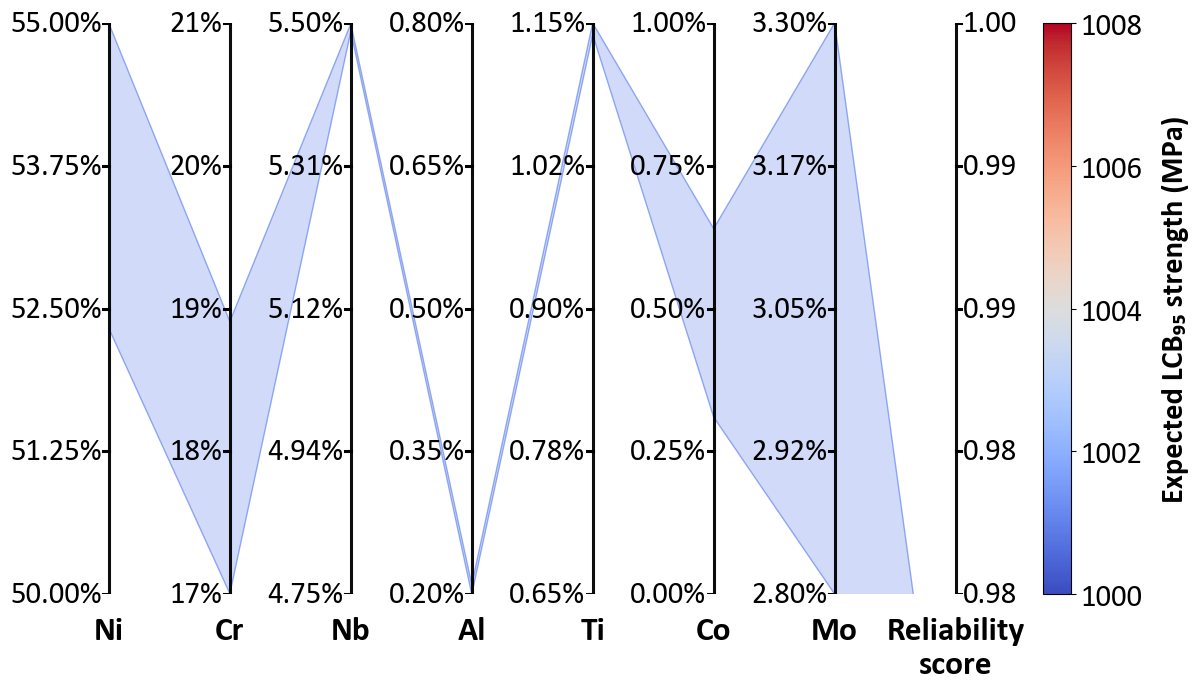

In [ ]:
# ---------------------------------------------------------
# Main workflow
# ---------------------------------------------------------

def main_7elements() -> None:
    """
    Run the complete uncertainty-aware Bayesian optimization workflow.
    """

    # Load dataset and surrogate model.
    df_bounds = load_dataset_for_bounds(DATASET_PATH)
    surrogate_model = load_surrogate_model(SURROGATE_MODEL_PATH)

    # Collect user-defined design requirements.
    min_required_strength = _prompt_float(
        "Minimum required strength (MPa)",
        default=1050,
    )

    sigma_threshold = _prompt_float(
        "Allowable total uncertainty threshold (MPa)",
        default=50,
    )

    reliability_pct = _prompt_float(
        "Target reliability (%)",
        default=95.0,
    )

    reliability_target = (
        reliability_pct / 100.0
        if reliability_pct > 1.0
        else reliability_pct
    )

    if not (0.0 < reliability_target <= 1.0):
        raise ValueError("Reliability must be provided as 0-1 or 0-100%.")

    weights = _prompt_weights(
        default=(0.5, 0.3, 0.2),
    )

    n_iters = _prompt_int(
        "Number of BO iterations",
        default=10,
    )

    batch_size = _prompt_int(
        "Batch size per iteration",
        default=10,
    )

    # Minimum allowable composition-window width for each element.
    min_deltas = _prompt_min_deltas()

    # Fixed demo settings.
    num_mc_samples = DEFAULT_NUM_MC_SAMPLES
    sigma_model = DEFAULT_SIGMA_MODEL
    z_inner = DEFAULT_Z_INNER

    # Derived design constraints.
    lb_lo = float(min_required_strength)
    lb_hi = float(min_required_strength + 0.5 * sigma_threshold)
    lb_window = (lb_lo, lb_hi)

    target_YS = float(min_required_strength)
    sigma_max = float(sigma_threshold)
    coverage_min = float(reliability_target)

    # Build Bayesian optimization objects.
    search_space = build_searchspace(
        df_bounds,
        min_deltas=min_deltas,
    )

    campaign = build_campaign(
        search_space,
        min_required_strength=min_required_strength,
        sigma_threshold=sigma_threshold,
        reliability_target=reliability_target,
        weights=weights,
    )

    OUTPUT_DIR_7ELEMENT.mkdir(
        parents=True,
        exist_ok=True,
    )

    full_df, filtered_df = run_bayesian_optimization(
        campaign=campaign,
        model=surrogate_model,
        n_iters=n_iters,
        batch_size=batch_size,
        num_mc_samples=num_mc_samples,
        target_YS=target_YS,
        sigma_model=sigma_model,
        z_inner=z_inner,
        lb_window=lb_window,
        sigma_max=sigma_max,
        coverage_min=coverage_min,
    )

    # Save full and filtered results.
    full_path = OUTPUT_DIR_7ELEMENT / "bo_measurements_full.csv"
    filtered_path = OUTPUT_DIR_7ELEMENT / "pareto_filtered.csv"

    full_df.to_csv(
        full_path,
        index=False,
    )

    filtered_df.to_csv(
        filtered_path,
        index=False,
    )

    print(f"\nSaved full BO measurements to: {full_path}")
    print(f"Saved filtered candidates to: {filtered_path}")

    if filtered_df.empty:
        print("\nNo candidates satisfied the filter criteria.")
        print(
            "Filter used: "
            f"LCB5% in [{lb_window[0]:.2f}, {lb_window[1]:.2f}] MPa, "
            f"Total uncertainty <= {sigma_max:.2f} MPa, "
            f"Coverage >= {coverage_min:.3f}"
        )
        return

    # Compute and save Pareto front.
    xcol = "Percentile LB over box (5%) (MPa)"
    ycol = "Total uncertainty"

    pareto_df, _ = pareto_front_2d(
        filtered_df,
        xcol=xcol,
        ycol=ycol,
        maximize_x=True,
        eps_y=0.2,
    )

    pareto_path = OUTPUT_DIR_7ELEMENT / "pareto_front.csv"

    pareto_df.to_csv(
        pareto_path,
        index=False,
    )

    print(f"Saved Pareto front to: {pareto_path}")

    # Display filtered candidates as the main notebook output.
    pd.set_option("display.max_rows", 200)
    pd.set_option("display.max_columns", 200)
    pd.set_option("display.width", 200)

    print("\nFiltered candidate windows:")
    print(filtered_df)

    # Optionally visualize one selected row.
    selected_index = _prompt_plot_row_index(len(filtered_df))

    if selected_index is None:
        print("No plot requested. Exiting.")
        return

    selected_row = filtered_df.iloc[selected_index]

    figure_path = OUTPUT_DIR_7ELEMENT / f"coordinate_plot_row_{selected_index}.png"

    fig = plot_coordinate_plot_single_row_like_reference(
        selected_row,
        pareto_df=pareto_df,
        target_YS=target_YS,
        out_path=figure_path,
        strength_col="Percentile LB over box (5%) (MPa)",
        coverage_candidates=(
            "Coverage over p_box",
            "Coverage over box p_x",
        ),
        prop_axis_label="Reliability\nscore",
        cb_label="Expected LCB₉₅ strength (MPa)",
    )

    print(f"Saved coordinate plot to: {figure_path}")

    plt.show()
    plt.close(fig)

main_7elements()

## Three-element inverse-design workflow

This demo runs the reduced design-space version of the inverse-design framework. In this case, only Nb, Al, and Ti are optimized by Bayesian optimization, while Ni, Cr, Co, and Mo are allowed to vary across their fixed Alloy 718 composition ranges.

This setup is useful for identifying the minimum set of must-control elements needed to satisfy a target strength, uncertainty threshold, and reliability requirement.

Running BO iteration 1/10
Running BO iteration 2/10


c:\Users\hasan\.conda\envs\ML\Lib\site-packages\botorch\models\utils\assorted.py:260: InputDataWarning: Data is not standardized (std = tensor([0.]), mean = tensor([0.])). Please consider scaling the input to zero mean and unit variance.
  check_standardization(Y=train_Y, raise_on_fail=raise_on_fail)


Running BO iteration 3/10
Running BO iteration 4/10


c:\Users\hasan\.conda\envs\ML\Lib\site-packages\botorch\optim\optimize.py:564: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 4 and message Inequality constraints incompatible.')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Running BO iteration 5/10
Running BO iteration 6/10
Running BO iteration 7/10
Running BO iteration 8/10
Running BO iteration 9/10
Running BO iteration 10/10

Saved: outputs\bo_measurements_full.csv
Saved: outputs\pareto_filtered.csv
Saved (not displayed): outputs\pareto_front.csv

Filtered dataset (final output):
     Nb_min    Nb_max    Al_min    Al_max    Ti_min    Ti_max  Ni_min  Ni_max  Cr_min  Cr_max  Co_min  Co_max  Mo_min  Mo_max  Predicted yield strength (MPa)  Compositional variation  \
0  4.779611  5.387051  0.271235  0.311725  1.046554  1.139046    50.0    55.0    17.0    21.0     0.0     1.0     2.8     3.3                     1115.033811                26.495837   
1  4.750029  5.369500  0.260449  0.324247  1.051632  1.149920    50.0    55.0    17.0    21.0     0.0     1.0     2.8     3.3                     1119.646787                29.216128   
2  5.477735  5.499837  0.200014  0.293182  1.139920  1.149920    50.0    55.0    17.0    21.0     0.0     1.0     2.8     3.3  

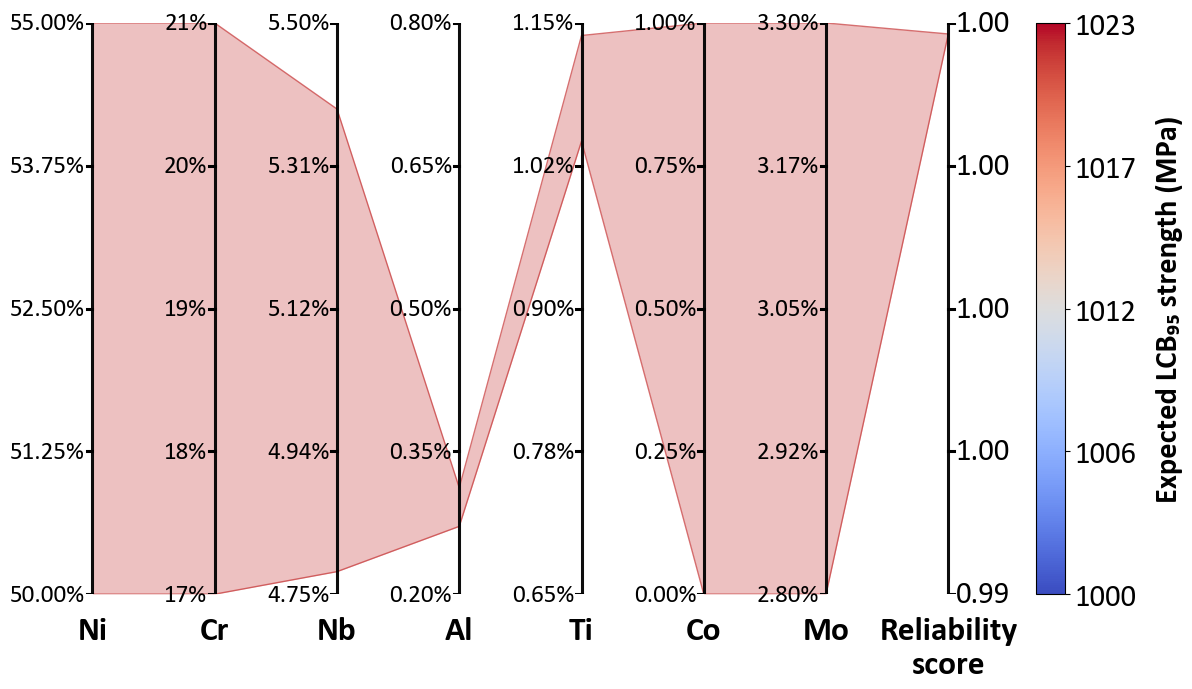

In [ ]:
from __future__ import annotations

import math
import pickle
from pathlib import Path
from typing import Dict, Optional, Tuple

import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.font_manager import FontProperties

from baybe import Campaign
from baybe.constraints import ContinuousLinearInequalityConstraint
from baybe.objective import DesirabilityObjective
from baybe.parameters import NumericalContinuousParameter
from baybe.recommenders import BotorchRecommender, RandomRecommender, TwoPhaseMetaRecommender
from baybe.searchspace import SearchSpace
from baybe.targets import NumericalTarget

np.random.seed(42)

# ----------------------------
# Configuration
# ----------------------------
ELEMENTS: Tuple[str, ...] = ("Ni", "Cr", "Nb", "Al", "Ti", "Co", "Mo")

DEFAULT_NUM_MC_SAMPLES = 1000
DEFAULT_SIGMA_MODEL = 30
DEFAULT_Z_INNER = 1.645
# ---------------------------------------------------------
# Configuration: three-element design workflow
# ---------------------------------------------------------

# Full element order expected by the trained PCE surrogate.
# The surrogate still predicts from all seven elements.
ELEMENTS: Tuple[str, ...] = ("Ni", "Cr", "Nb", "Al", "Ti", "Co", "Mo")

# Elements actively optimized in the reduced design space.
OPTIMIZED_ELEMENTS: Tuple[str, ...] = ("Nb", "Al", "Ti")

# Elements not optimized directly.
# These are sampled across their fixed global ranges during each candidate evaluation.
BACKGROUND_ELEMENTS: Tuple[str, ...] = ("Ni", "Cr", "Co", "Mo")

# Dataset used only to define composition bounds.
# Replace this placeholder path with your own local dataset.
DATASET_PATH = Path("../data/example_alloy718_dataset.csv")

# Trained PCE surrogate model.
# The model file is not included in the GitHub repository.
SURROGATE_MODEL_PATH = Path("../model/pce_surrogate.pkl")

DEFAULT_NUM_MC_SAMPLES = 1000

# Calibrated model uncertainty from Bayesian calibration.
DEFAULT_SIGMA_MODEL = 30.0

# One-sided 95% normal critical value used for LCB95.
DEFAULT_Z_INNER = 1.645

# Global Alloy 718 ranges in wt.%.
# In the 3-element workflow:
#   - Nb, Al, Ti bounds are optimized.
#   - Ni, Cr, Co, Mo are sampled from the fixed ranges below.
DEFAULT_RANGES_WT = {
    "Ni": (50.0, 55.0),
    "Cr": (17.0, 21.0),
    "Nb": (4.75, 5.50),
    "Al": (0.20, 0.80),
    "Ti": (0.65, 1.15),
    "Co": (0.00, 1.00),
    "Mo": (2.80, 3.30),
}

OUTPUT_DIR_3ELEMENT = Path("outputs_3element")


def suggest_range_with_coverage_3elem(
    dataframe: pd.DataFrame,
    num_samples: int,
    model,
    sigma_model: float,
    target_YS: float,
    z_inner: float = DEFAULT_Z_INNER,
    fixed_ranges_wt: dict[str, tuple[float, float]] = DEFAULT_RANGES_WT,
) -> Tuple[list, list, list, list, list, list]:
    """
    Evaluate candidate composition windows for the three-element design workflow.

    In this reduced design space, the optimizer controls only:

        Nb_min, Nb_max, Al_min, Al_max, Ti_min, Ti_max

    The remaining elements, Ni, Cr, Co, and Mo, are not optimized directly.
    Instead, they are sampled across their fixed global Alloy 718 ranges.

    The PCE surrogate still receives all seven elements in the order:

        [Ni, Cr, Nb, Al, Ti, Co, Mo]

    Returns
    -------
    tuple of lists
        mean_strength :
            Mean predicted yield strength over the sampled window.
        sigma_prop :
            Composition-driven standard deviation of predicted strength.
        sigma_total :
            Total uncertainty, sqrt(sigma_prop^2 + sigma_model^2).
        lb05_over_box :
            5th percentile of LCB95 values across the sampled window.
        coverage_prop :
            Fraction of sampled compositions satisfying the target.
        coverage_lb :
            Wilson 95% lower confidence bound for coverage.
    """

    required_columns = []

    for element in OPTIMIZED_ELEMENTS:
        required_columns += [f"{element}_min", f"{element}_max"]

    missing = [column for column in required_columns if column not in dataframe.columns]

    if missing:
        raise KeyError(
            "The 3-element candidate DataFrame is missing required columns:\n"
            f"{missing}"
        )

    mean_strength = []
    sigma_prop = []
    sigma_total = []
    lb05_over_box = []
    coverage_prop = []
    coverage_lb = []

    sigma_model = float(sigma_model)
    target_YS = float(target_YS)

    for _, row in dataframe.iterrows():
        # Optimized elements are sampled from the BO-proposed candidate window.
        Nb = _uniform_range(row["Nb_min"], row["Nb_max"], num_samples)
        Al = _uniform_range(row["Al_min"], row["Al_max"], num_samples)
        Ti = _uniform_range(row["Ti_min"], row["Ti_max"], num_samples)

        # Background elements are sampled from fixed global ranges.
        Ni = _uniform_range(*fixed_ranges_wt["Ni"], num_samples)
        Cr = _uniform_range(*fixed_ranges_wt["Cr"], num_samples)
        Co = _uniform_range(*fixed_ranges_wt["Co"], num_samples)
        Mo = _uniform_range(*fixed_ranges_wt["Mo"], num_samples)

        # Full seven-element input required by the PCE surrogate.
        X = np.vstack([Ni, Cr, Nb, Al, Ti, Co, Mo]).T

        mu_i = np.asarray(model(*X.T), dtype=float).reshape(-1)

        lcb_i = mu_i - z_inner * sigma_model
        safe = lcb_i >= target_YS

        p_hat = float(np.mean(safe))
        p_lb = _wilson_lower_95(p_hat, len(mu_i))

        q05_lb = float(np.quantile(lcb_i, 0.05))

        s_comp = float(np.std(mu_i, ddof=1))
        s_tot = math.sqrt(s_comp**2 + sigma_model**2)

        mean_strength.append(float(np.mean(mu_i)))
        sigma_prop.append(s_comp)
        sigma_total.append(s_tot)
        lb05_over_box.append(q05_lb)
        coverage_prop.append(p_hat)
        coverage_lb.append(p_lb)

    return (
        mean_strength,
        sigma_prop,
        sigma_total,
        lb05_over_box,
        coverage_prop,
        coverage_lb,
    )


# ---------------------------------------------------------
# 3) BayBE: search space + campaign (3 elements only)
# ---------------------------------------------------------
def build_searchspace_3elem(
    df: pd.DataFrame,
    *,
    min_deltas: Dict[str, float],
) -> SearchSpace:
    """
    Build the BayBE search space for the reduced Nb-Al-Ti design workflow.

    Only the following variables are optimized:

        Nb_min, Nb_max
        Al_min, Al_max
        Ti_min, Ti_max

    Bounds are derived from the dataset columns:

        "Nb (wt%)", "Al (wt%)", "Ti (wt%)"

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset used to define elemental bounds.
    min_deltas : dict
        Minimum allowable composition-window width for Nb, Al, and Ti.

    Returns
    -------
    SearchSpace
        Constrained BayBE search space for the three optimized elements.
    """

    def _bounds(column: str) -> Tuple[float, float]:
        values = pd.to_numeric(df[column], errors="coerce").to_numpy(dtype=float)

        lo = float(np.nanmin(values))
        hi = float(np.nanmax(values))

        if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
            raise ValueError(
                f"Invalid bounds obtained from column '{column}': "
                f"lower={lo}, upper={hi}"
            )

        return lo, hi

    parameters = []

    for element in OPTIMIZED_ELEMENTS:
        column = f"{element} (wt%)"
        lo, hi = _bounds(column)

        parameters.append(
            NumericalContinuousParameter(
                f"{element}_min",
                bounds=(lo, hi),
            )
        )

        parameters.append(
            NumericalContinuousParameter(
                f"{element}_max",
                bounds=(lo, hi),
            )
        )

    constraints = []

    for element in OPTIMIZED_ELEMENTS:
        eps = float(min_deltas[element])

        if eps <= 0:
            raise ValueError(
                f"Minimum allowable window width for {element} must be > 0. "
                f"Received {eps}."
            )

        constraints.append(
            ContinuousLinearInequalityConstraint(
                parameters=[f"{element}_max", f"{element}_min"],
                coefficients=[1.0, -1.0],
                rhs=eps,
            )
        )

    return SearchSpace.from_product(
        parameters=parameters,
        constraints=constraints,
    )

# ---------------------------------------------------------
# 4) Run Bayesian optimization (3 elements)
# ---------------------------------------------------------
def run_bayesian_optimization_3elem(
    campaign: Campaign,
    model,
    *,
    n_iters: int,
    batch_size: int,
    num_mc_samples: int,
    target_YS: float,
    sigma_model: float,
    z_inner: float,
    lb_window: Tuple[float, float],
    sigma_max: float,
    coverage_min: Optional[float],
    fixed_ranges_wt: dict[str, tuple[float, float]] = DEFAULT_RANGES_WT,
) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """
    Run Bayesian optimization for the reduced Nb-Al-Ti design space.

    BayBE recommends candidate windows only for Nb, Al, and Ti. During
    evaluation, Ni, Cr, Co, and Mo are sampled across their fixed global ranges
    so that robustness is assessed under variation in the non-optimized
    background elements.
    """

    if n_iters <= 0:
        raise ValueError("n_iters must be positive.")

    if batch_size <= 0:
        raise ValueError("batch_size must be positive.")

    if num_mc_samples <= 0:
        raise ValueError("num_mc_samples must be positive.")

    for iteration in range(n_iters):
        print(f"Running BO iteration {iteration + 1}/{n_iters}")

        iter_df = campaign.recommend(batch_size=batch_size)

        (
            mean_strength,
            sigma_comp,
            sigma_total,
            lb5,
            coverage_p,
            coverage_lb,
        ) = suggest_range_with_coverage_3elem(
            dataframe=iter_df,
            num_samples=num_mc_samples,
            model=model,
            sigma_model=sigma_model,
            target_YS=target_YS,
            z_inner=z_inner,
            fixed_ranges_wt=fixed_ranges_wt,
        )

        # Add fixed min/max columns for the background elements.
        # This keeps the output format compatible with plotting and saving.
        for element in BACKGROUND_ELEMENTS:
            iter_df[f"{element}_min"] = fixed_ranges_wt[element][0]
            iter_df[f"{element}_max"] = fixed_ranges_wt[element][1]

        iter_df["Predicted yield strength (MPa)"] = mean_strength
        iter_df["Compositional variation"] = sigma_comp
        iter_df["Total uncertainty"] = sigma_total
        iter_df["Percentile LB over box (5%) (MPa)"] = lb5
        iter_df["Coverage over box p_x"] = coverage_p
        iter_df["Coverage over box LB (95% CI)"] = coverage_lb

        campaign.add_measurements(iter_df)

    full_data = campaign.measurements.copy()

    mask = (
        full_data["Percentile LB over box (5%) (MPa)"].between(
            lb_window[0],
            lb_window[1],
            inclusive="both",
        )
        & (full_data["Total uncertainty"] <= float(sigma_max))
    )

    if coverage_min is not None:
        mask &= full_data["Coverage over box p_x"] >= float(coverage_min)

    filtered_data = (
        full_data.loc[mask]
        .sort_values("Total uncertainty", ascending=True)
        .reset_index(drop=True)
    )

    return full_data, filtered_data

# ---------------------------------------------------------
# 7) CLI prompts + main
# ---------------------------------------------------------

def _prompt_min_deltas_3elem() -> Dict[str, float]:
    """
    Prompt for minimum allowable composition-window widths for Nb, Al, and Ti.

    The user can enter either:

        1. one value applied to all three elements, or
        2. three comma-separated values in the order Nb, Al, Ti.
    """

    while True:
        raw = input(
            "Minimum allowable difference between max and min values for Nb, Al, and Ti. "
            "Enter one value for all three elements, or 3 comma-separated values "
            "for Nb,Al,Ti [default=0.01]: "
        ).strip()

        if raw == "":
            return {
                "Nb": 0.01,
                "Al": 0.01,
                "Ti": 0.01,
            }

        parts = [part.strip() for part in raw.split(",") if part.strip() != ""]

        try:
            if len(parts) == 1:
                value = float(parts[0])

                if value <= 0:
                    print("Value must be greater than 0.")
                    continue

                return {
                    "Nb": value,
                    "Al": value,
                    "Ti": value,
                }

            if len(parts) == 3:
                values = [float(part) for part in parts]

                if any(value <= 0 for value in values):
                    print("All values must be greater than 0.")
                    continue

                return {
                    "Nb": values[0],
                    "Al": values[1],
                    "Ti": values[2],
                }

            print("Please enter either 1 value or exactly 3 comma-separated values.")

        except ValueError:
            print("Please enter valid numerical values.")

def main_3elements() -> None:
    """
    Run the reduced three-element inverse-design workflow.

    Only Nb, Al, and Ti are optimized. Ni, Cr, Co, and Mo are sampled across
    their fixed Alloy 718 ranges when each candidate window is evaluated.
    """

    df_bounds = load_dataset_for_bounds(DATASET_PATH)
    surrogate_model = load_surrogate_model(SURROGATE_MODEL_PATH)

    min_required_strength = _prompt_float(
        "Minimum required strength (MPa)",
        default=1000.0,
    )

    sigma_threshold = _prompt_float(
        "Allowable total uncertainty threshold (MPa)",
        default=45.0,
    )

    reliability_pct = _prompt_float(
        "Target reliability (%)",
        default=95.0,
    )

    reliability_target = (
        reliability_pct / 100.0
        if reliability_pct > 1.0
        else reliability_pct
    )

    if not (0.0 < reliability_target <= 1.0):
        raise ValueError("Reliability must be provided as 0-1 or 0-100%.")

    weights = _prompt_weights(
        default=(0.5, 0.3, 0.2),
    )

    n_iters = _prompt_int(
        "Number of BO iterations",
        default=10,
    )

    batch_size = _prompt_int(
        "Batch size per iteration",
        default=10,
    )

    # Minimum allowable window widths are requested only for Nb, Al, and Ti.
    min_deltas = _prompt_min_deltas_3elem()

    num_mc_samples = DEFAULT_NUM_MC_SAMPLES
    sigma_model = DEFAULT_SIGMA_MODEL
    z_inner = DEFAULT_Z_INNER

    lb_lo = float(min_required_strength)
    lb_hi = float(min_required_strength + 0.5 * sigma_threshold)
    lb_window = (lb_lo, lb_hi)

    target_YS = float(min_required_strength)
    sigma_max = float(sigma_threshold)
    coverage_min = float(reliability_target)

    search_space = build_searchspace_3elem(
        df_bounds,
        min_deltas=min_deltas,
    )

    campaign = build_campaign(
        search_space,
        min_required_strength=min_required_strength,
        sigma_threshold=sigma_threshold,
        reliability_target=reliability_target,
        weights=weights,
    )

    OUTPUT_DIR.mkdir(
        parents=True,
        exist_ok=True,
    )

    full_df, filtered_df = run_bayesian_optimization_3elem(
        campaign=campaign,
        model=surrogate_model,
        n_iters=n_iters,
        batch_size=batch_size,
        num_mc_samples=num_mc_samples,
        target_YS=target_YS,
        sigma_model=sigma_model,
        z_inner=z_inner,
        lb_window=lb_window,
        sigma_max=sigma_max,
        coverage_min=coverage_min,
        fixed_ranges_wt=DEFAULT_RANGES_WT,
    )

    full_path = OUTPUT_DIR / "bo_measurements_full_3element.csv"
    filtered_path = OUTPUT_DIR / "filtered_candidates_3element.csv"

    full_df.to_csv(
        full_path,
        index=False,
    )

    filtered_df.to_csv(
        filtered_path,
        index=False,
    )

    print(f"\nSaved full BO measurements to: {full_path}")
    print(f"Saved filtered candidates to: {filtered_path}")

    if filtered_df.empty:
        print("\nNo candidates satisfied the filter criteria.")
        print(
            "Filter used: "
            f"LCB5% in [{lb_window[0]:.2f}, {lb_window[1]:.2f}] MPa, "
            f"Total uncertainty <= {sigma_max:.2f} MPa, "
            f"Coverage >= {coverage_min:.3f}"
        )
        return

    xcol = "Percentile LB over box (5%) (MPa)"
    ycol = "Total uncertainty"

    pareto_df, _ = pareto_front_2d(
        filtered_df,
        xcol=xcol,
        ycol=ycol,
        maximize_x=True,
        eps_y=0.2,
    )

    pareto_path = OUTPUT_DIR / "pareto_front_3element.csv"

    pareto_df.to_csv(
        pareto_path,
        index=False,
    )

    print(f"Saved Pareto front to: {pareto_path}")

    pd.set_option("display.max_rows", 200)
    pd.set_option("display.max_columns", 200)
    pd.set_option("display.width", 200)

    print("\nFiltered candidate windows from the three-element workflow:")
    print(filtered_df)

    selected_index = _prompt_plot_row_index(len(filtered_df))

    if selected_index is None:
        print("No plot requested. Exiting.")
        return

    selected_row = filtered_df.iloc[selected_index]

    figure_path = OUTPUT_DIR_3ELEMENT / f"coordinate_plot_3element_row_{selected_index}.png"

    fig = plot_coordinate_plot_single_row_like_reference(
        selected_row,
        pareto_df=pareto_df,
        target_YS=target_YS,
        out_path=figure_path,
        strength_col=xcol,
        coverage_candidates=(
            "Coverage over p_box",
            "Coverage over box p_x",
        ),
        prop_axis_label="Reliability\nscore",
        cb_label="Expected LCB₉₅ strength (MPa)",
    )

    print(f"Saved coordinate plot to: {figure_path}")

    plt.show()
    plt.close(fig)


main_3elements()